# 🌧️ Associação entre Precipitação e Gravidade dos Acidentes em Rodovias Federais no Estado de São Paulo

**Disciplina:** ACH0042 - Resolução de Problemas II  
**Autores:** Gustavo Henrique Ferreira Alves, Gustavo Lima de Souza e Guilherme Padun Santos

## Objetivo

Avaliar a associação entre a precipitação registrada por estações meteorológicas e a gravidade dos acidentes em rodovias federais no estado de São Paulo.

## Período da análise

A análise utiliza os registros de acidentes de **2025 completo** e os dados disponíveis de **2026, atualmente de janeiro a maio**.

## Fontes de dados

- **PRF:** bases `datatran2025.csv` e `datatran2026.csv`, agrupadas por ocorrência.
- **INMET:** medições horárias das estações meteorológicas automáticas.

## Fluxo

**PRF 2025–2026 → Preparação dos acidentes → INMET 2025–2026 → Preparação das estações → Integração espacial e temporal → Validação → Análise descritiva → Regressão Logística Ordinal**

# 1. Configuração do ambiente

O código oficial do projeto fica no GitHub. O Colab é utilizado para executar o pipeline e acessar os arquivos grandes do INMET armazenados no Google Drive.

In [ ]:
from pathlib import Path

CAMINHO_PROJETO = Path("/content/RP2")
BRANCH = "main"

if not CAMINHO_PROJETO.exists():
    !git clone https://github.com/LimaGustav/RP2.git
    %cd /content/RP2
else:
    %cd /content/RP2

!git fetch origin
!git switch $BRANCH
!git pull origin $BRANCH

!pip install -q -r requirements.txt

print("Projeto atualizado e ambiente configurado.")
print("Branch atual:")
!git branch --show-current

/content/RP2
remote: Enumerating objects: 8, done.
remote: Counting objects: 100% (8/8), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 5 (delta 3), reused 4 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 7.16 KiB | 2.39 MiB/s, done.
From https://github.com/LimaGustav/RP2
   82c96e6..c132bc3  main       -> origin/main
 * [new branch]      feat/ajusta-modelagem-final -> origin/feat/ajusta-modelagem-final
Already on 'main'
Your branch is behind 'origin/main' by 2 commits, and can be fast-forwarded.
  (use "git pull" to update your local branch)
From https://github.com/LimaGustav/RP2
 * branch            main       -> FETCH_HEAD
Updating 82c96e6..c132bc3
Fast-forward
 src/05_regressao_ordinal.py | 1797 +++++++++++++++++++++++++++++++++----------
 1 file changed, 1381 insertions(+), 416 deletions(-)
Projeto atualizado e ambiente configurado.
Branch atual:
main


# 2. Preparação dos dados da PRF

As bases `datatran2025.csv` e `datatran2026.csv` são agrupadas por ocorrência, de forma que cada linha representa um acidente.

Nesta etapa são realizadas:

- leitura e concatenação dos dois anos;
- filtragem dos acidentes de São Paulo;
- tratamento de datas, horários e coordenadas;
- criação das variáveis `ano` e `mes`;
- seleção dos registros de 2025 e dos dados disponíveis de 2026;
- codificação ordinal da gravidade.

In [ ]:
from pathlib import Path

PASTA_PRF = Path(
    "/content/RP2/datasets/raw/prf"
)

arquivos_esperados = [
    PASTA_PRF / "datatran2025.csv",
    PASTA_PRF / "datatran2026.csv",
]

faltando = [
    str(arquivo)
    for arquivo in arquivos_esperados
    if not arquivo.exists()
]

if faltando:
    raise FileNotFoundError(
        "Arquivos da PRF ausentes:\n- "
        + "\n- ".join(faltando)
    )

print("Bases da PRF encontradas:")

for arquivo in arquivos_esperados:
    print("-", arquivo.name)

Bases da PRF encontradas:
- datatran2025.csv
- datatran2026.csv


In [ ]:
!python src/01_preparar_prf.py

PREPARAÇÃO DOS DADOS DA PRF

Arquivos encontrados:
- datatran2025.csv
- datatran2026.csv

Carregando datatran2025.csv...
Registros carregados: 72,529

Carregando datatran2026.csv...
Registros carregados: 29,774

Total antes dos filtros: 102,303

Registros de SP antes do filtro temporal: 6,515

Registros de SP por arquivo:
arquivo_origem
datatran2025.csv    4683
datatran2026.csv    1832
Name: count, dtype: int64

Validação das datas por arquivo:
                  total  validas  invalidas
arquivo_origem                             
datatran2025.csv   4683     4683          0
datatran2026.csv   1832     1832          0

Exemplos das datas originais:
datatran2025.csv -> ['2025-01-01', '2025-01-03', '2025-01-03', '2025-01-03', '2025-01-04']
datatran2026.csv -> ['01/01/2026', '02/01/2026', '03/01/2026', '04/01/2026', '05/01/2026']

Ano identificado antes do filtro:
ano
2025    4683
2026    1832
Name: count, dtype: int64

Quantidade de acidentes após filtro por ano:
6515

Acidentes por ano:


In [ ]:
import pandas as pd

prf = pd.read_csv(
    "datasets/processed/acidentes_sp.csv"
)

print(f"Quantidade total de acidentes: {len(prf):,}")
print()

print("Acidentes por ano:")
display(
    prf["ano"]
    .value_counts()
    .sort_index()
    .rename("acidentes")
    .to_frame()
)

print("Gravidade por ano:")
display(
    pd.crosstab(
        prf["ano"],
        prf["classificacao_acidente"]
    )
)

display(prf.head())

Quantidade total de acidentes: 6,515

Acidentes por ano:


,acidentes
ano,
2025,4683
2026,1832


Gravidade por ano:


classificacao_acidente,Com Vítimas Fatais,Com Vítimas Feridas,Sem Vítimas
ano,,,
2025,205,3779,699
2026,66,1494,272


,id,data_inversa,horario,uf,br,km,municipio,latitude,longitude,classificacao_acidente,...,tipo_pista,tracado_via,mortos,feridos_graves,feridos_leves,arquivo_origem,ano,mes,data_hora,gravidade_ordinal
0,652476,2025-01-01,01:30:00,SP,116,6.7,QUELUZ,-22.531582,-44.753747,Com Vítimas Feridas,...,Dupla,Reta,0,0,2,datatran2025.csv,2025,1,2025-01-01 01:30:00,1
1,652493,2025-01-01,06:20:00,SP,116,225.0,GUARULHOS,-23.485868,-46.540753,Com Vítimas Feridas,...,Múltipla,Reta;Declive,0,0,1,datatran2025.csv,2025,1,2025-01-01 06:20:00,1
2,652516,2025-01-01,07:53:00,SP,381,37.4,ATIBAIA,-23.105062,-46.568816,Sem Vítimas,...,Dupla,Reta,0,0,0,datatran2025.csv,2025,1,2025-01-01 07:53:00,0
3,652658,2025-01-01,10:15:00,SP,101,46.0,UBATUBA,-23.424034,-45.074921,Com Vítimas Feridas,...,Simples,Reta,0,0,1,datatran2025.csv,2025,1,2025-01-01 10:15:00,1
4,652601,2025-01-01,17:00:00,SP,116,564.0,BARRA DO TURVO,-25.050147,-48.553734,Com Vítimas Feridas,...,Simples,Curva,0,0,1,datatran2025.csv,2025,1,2025-01-01 17:00:00,1


# 3. Preparação dos dados meteorológicos do INMET

Os arquivos do INMET ficam no Google Drive para evitar o versionamento de centenas de CSVs no GitHub.

Estrutura esperada no Drive:

```text
Meu Drive/
└── RP2/
    └── INMET/
        ├── 2025/
        │   └── arquivos CSV do INMET
        └── 2026/
            └── arquivos CSV do INMET
```

O notebook copia somente os arquivos de estações de **São Paulo**, preservando a separação por ano.

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

PASTA_DRIVE_INMET = Path(
    "/content/drive/MyDrive/RP2/INMET"
)

PASTA_INMET_PROJETO = Path(
    "/content/RP2/datasets/raw/inmet"
)

print("Pasta do INMET no Drive:", PASTA_DRIVE_INMET)
print("Destino temporário no projeto:", PASTA_INMET_PROJETO)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pasta do INMET no Drive: /content/drive/MyDrive/RP2/INMET
Destino temporário no projeto: /content/RP2/datasets/raw/inmet


In [ ]:
import shutil

ANOS = [2025, 2026]

# Limpa os dados temporários da execução anterior no Colab
if PASTA_INMET_PROJETO.exists():
    shutil.rmtree(PASTA_INMET_PROJETO)

PASTA_INMET_PROJETO.mkdir(
    parents=True,
    exist_ok=True
)

resumo_copia = []

for ano in ANOS:
    origem = PASTA_DRIVE_INMET / str(ano)
    destino = PASTA_INMET_PROJETO / str(ano)

    if not origem.exists():
        raise FileNotFoundError(
            f"Pasta do INMET não encontrada no Drive: {origem}"
        )

    destino.mkdir(
        parents=True,
        exist_ok=True
    )

    arquivos = [
        arquivo
        for arquivo in origem.rglob("*")
        if arquivo.is_file()
        and arquivo.suffix.lower() == ".csv"
        and arquivo.name.upper().startswith("INMET_")
    ]

    arquivos_sp = [
        arquivo
        for arquivo in arquivos
        if "_SP_" in arquivo.name.upper()
    ]

    for arquivo in arquivos_sp:
        shutil.copy2(
            arquivo,
            destino / arquivo.name
        )

    resumo_copia.append(
        {
            "ano": ano,
            "arquivos_inmet": len(arquivos),
            "arquivos_sp": len(arquivos_sp),
        }
    )

display(pd.DataFrame(resumo_copia))

print("Arquivos do INMET copiados para o ambiente do Colab.")

,ano,arquivos_inmet,arquivos_sp
0,2025,594,40
1,2026,639,40


Arquivos do INMET copiados para o ambiente do Colab.


In [ ]:
!python src/02_preparar_inmet.py

Arquivos de SP encontrados: 80

Arquivos encontrados por pasta:
2025: 40
2026: 40
OK: 2025/INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A705_BAURU_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A706_CAMPOS DO JORDAO_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A707_PRESIDENTE PRUDENTE_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A708_FRANCA_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A711_SAO CARLOS_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A712_IGUAPE_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A713_IPERO_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A714_ITAPEVA_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A715_SAO MIGUEL ARCANJO_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A716_OURINHOS_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A718_RANCHARIA_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A725_AVARE_01-01-2025_A_31-12-2025.CSV
OK: 2025/INMET_SE_SP_A726_PIRACICABA_01-01-2025_A_31-12-2025.CSV
OK: 2

In [ ]:
inmet = pd.read_csv(
    "datasets/processed/inmet_sp.csv"
)

print(f"Registros meteorológicos: {len(inmet):,}")
print(f"Estações únicas no conjunto completo: {inmet['codigo_wmo'].nunique()}")

print("\nRegistros por ano:")
display(
    inmet["ano"]
    .value_counts()
    .sort_index()
    .rename("registros")
    .to_frame()
)

print("Estações por ano:")
display(
    inmet.groupby("ano")["codigo_wmo"]
    .nunique()
    .rename("estacoes")
    .to_frame()
)

display(inmet.head())

Registros meteorológicos: 583,680
Estações únicas no conjunto completo: 40

Registros por ano:


,registros
ano,
2024,120
2025,350400
2026,233160


Estações por ano:


,estacoes
ano,
2024,40
2025,40
2026,40


,data,hora_utc,precipitacao_mm,codigo_wmo,estacao,uf_estacao,latitude_estacao,longitude_estacao,arquivo_origem,data_hora_utc,data_hora_sp,ano,mes
0,2025/01/01,0,0.0,A701,SAO PAULO - MIRANTE,SP,-23.496289,-46.620067,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-202...,2025-01-01 00:00:00+00:00,2024-12-31 21:00:00,2024,12
1,2025/01/01,0,0.0,A705,BAURU,SP,-22.358056,-49.028889,INMET_SE_SP_A705_BAURU_01-01-2025_A_31-12-2025...,2025-01-01 00:00:00+00:00,2024-12-31 21:00:00,2024,12
2,2025/01/01,0,0.0,A706,CAMPOS DO JORDAO,SP,-22.750278,-45.603889,INMET_SE_SP_A706_CAMPOS DO JORDAO_01-01-2025_A...,2025-01-01 00:00:00+00:00,2024-12-31 21:00:00,2024,12
3,2025/01/01,0,0.0,A707,PRESIDENTE PRUDENTE,SP,-22.120000,-51.408611,INMET_SE_SP_A707_PRESIDENTE PRUDENTE_01-01-202...,2025-01-01 00:00:00+00:00,2024-12-31 21:00:00,2024,12
4,2025/01/01,0,NaN,A708,FRANCA,SP,-20.584444,-47.382500,INMET_SE_SP_A708_FRANCA_01-01-2025_A_31-12-202...,2025-01-01 00:00:00+00:00,2024-12-31 21:00:00,2024,12


# 4. Integração PRF–INMET

Cada acidente é associado:

- **espacialmente:** à estação meteorológica mais próxima;
- **temporalmente:** à medição mais próxima do horário do acidente.

A distância acidente–estação e a diferença temporal são preservadas para avaliação posterior da qualidade da associação.

In [ ]:
from pathlib import Path

arquivo_prf = Path(
    "datasets/processed/acidentes_sp.csv"
)

arquivo_inmet = Path(
    "datasets/processed/inmet_sp.csv"
)

print(
    "PRF preparada:",
    "Tudo Certo" if arquivo_prf.exists() else "Erro!!!"
)

print(
    "INMET preparado:",
    "Tudo Certo" if arquivo_inmet.exists() else "Erro!!!"
)

if not arquivo_prf.exists() or not arquivo_inmet.exists():
    raise FileNotFoundError(
        "Execute as etapas de preparação da PRF e do INMET antes da integração."
    )

PRF preparada: Tudo Certo
INMET preparado: Tudo Certo


In [ ]:
!python src/03_integrar_bases.py

100/6515 acidentes processados
200/6515 acidentes processados
300/6515 acidentes processados
400/6515 acidentes processados
500/6515 acidentes processados
600/6515 acidentes processados
700/6515 acidentes processados
800/6515 acidentes processados
900/6515 acidentes processados
1000/6515 acidentes processados
1100/6515 acidentes processados
1200/6515 acidentes processados
1300/6515 acidentes processados
1400/6515 acidentes processados
1500/6515 acidentes processados
1600/6515 acidentes processados
1700/6515 acidentes processados
1800/6515 acidentes processados
1900/6515 acidentes processados
2000/6515 acidentes processados
2100/6515 acidentes processados
2200/6515 acidentes processados
2300/6515 acidentes processados
2400/6515 acidentes processados
2500/6515 acidentes processados
2600/6515 acidentes processados
2700/6515 acidentes processados
2800/6515 acidentes processados
2900/6515 acidentes processados
3000/6515 acidentes processados
3100/6515 acidentes processados
3200/6515 acident

In [ ]:
base = pd.read_csv(
    "datasets/processed/base_integrada.csv"
)

print(f"Acidentes na base integrada: {len(base):,}")

print("\nStatus da integração por ano:")
display(
    pd.crosstab(
        base["ano"],
        base["status_integracao"]
    )
)

display(base.head())

Acidentes na base integrada: 6,515

Status da integração por ano:


status_integracao,integrado,precipitacao_ausente
ano,,
2025,3982,701
2026,1679,153


,id,data_inversa,horario,uf,br,km,municipio,latitude,longitude,classificacao_acidente,...,mes,data_hora,gravidade_ordinal,codigo_wmo,estacao_inmet,distancia_estacao_km,data_hora_medicao,diferenca_tempo_min,precipitacao_mm,status_integracao
0,652476,2025-01-01,01:30:00,SP,116,6.7,QUELUZ,-22.531582,-44.753747,Com Vítimas Feridas,...,1,2025-01-01 01:30:00,1,A769,CACHOEIRA PAULISTA,31.210085,2025-01-01 01:00:00,30.0,0.0,integrado
1,652493,2025-01-01,06:20:00,SP,116,225.0,GUARULHOS,-23.485868,-46.540753,Com Vítimas Feridas,...,1,2025-01-01 06:20:00,1,A701,SAO PAULO - MIRANTE,8.170914,2025-01-01 06:00:00,20.0,0.0,integrado
2,652516,2025-01-01,07:53:00,SP,381,37.4,ATIBAIA,-23.105062,-46.568816,Sem Vítimas,...,1,2025-01-01 07:53:00,0,A744,BRAGANCA PAULISTA,17.877196,2025-01-01 08:00:00,7.0,0.0,integrado
3,652658,2025-01-01,10:15:00,SP,101,46.0,UBATUBA,-23.424034,-45.074921,Com Vítimas Feridas,...,1,2025-01-01 10:15:00,1,A740,SAO LUIZ DO PARAITINGA,41.147732,2025-01-01 10:00:00,15.0,NaN,precipitacao_ausente
4,652601,2025-01-01,17:00:00,SP,116,564.0,BARRA DO TURVO,-25.050147,-48.553734,Com Vítimas Feridas,...,1,2025-01-01 17:00:00,1,A746,BARRA DO TURVO,16.909736,2025-01-01 17:00:00,0.0,9.0,integrado


# 5. Validação da base integrada

Antes da modelagem estatística, avaliamos:

- quantidade de acidentes por ano;
- distribuição da gravidade;
- disponibilidade de precipitação;
- distância entre acidente e estação;
- diferença temporal entre acidente e medição;
- comparação entre a condição meteorológica registrada pela PRF e a precipitação medida pelo INMET;
- impacto de diferentes limites máximos de distância entre acidente e estação;
- possíveis valores extremos de precipitação.

In [ ]:
print("Resumo por ano:")

resumo_ano = (
    base.groupby("ano")
    .agg(
        acidentes=("id", "count"),
        precipitacao_valida=(
            "precipitacao_mm",
            lambda x: x.notna().sum()
        ),
        distancia_mediana_km=(
            "distancia_estacao_km",
            "median"
        ),
        diferenca_temporal_mediana_min=(
            "diferenca_tempo_min",
            "median"
        ),
    )
)

resumo_ano["percentual_precipitacao_valida"] = (
    resumo_ano["precipitacao_valida"]
    / resumo_ano["acidentes"]
    * 100
)

display(resumo_ano)

Resumo por ano:


,acidentes,precipitacao_valida,distancia_mediana_km,diferenca_temporal_mediana_min,percentual_precipitacao_valida
ano,,,,,
2025,4683,3982,21.564004,15.0,85.030963
2026,1832,1679,21.890865,15.0,91.648472


In [ ]:
print("Distribuição da gravidade por ano:")

display(
    pd.crosstab(
        base["ano"],
        base["classificacao_acidente"]
    )
)

Distribuição da gravidade por ano:


classificacao_acidente,Com Vítimas Fatais,Com Vítimas Feridas,Sem Vítimas
ano,,,
2025,205,3779,699
2026,66,1494,272


In [ ]:
print("Percentis da distância até a estação (km):")

display(
    base["distancia_estacao_km"]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95
        ]
    )
    .to_frame("distancia_km")
)

print("Percentis da diferença temporal (min):")

display(
    base["diferenca_tempo_min"]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95
        ]
    )
    .to_frame("diferenca_min")
)

Percentis da distância até a estação (km):


,distancia_km
count,6515.000000
mean,26.226732
std,18.347061
min,0.252347
25%,12.089922
50%,21.651967
75%,39.159348
90%,54.916586
95%,64.249301
max,81.842281


Percentis da diferença temporal (min):


,diferenca_min
count,6515.000000
mean,14.769762
std,10.246236
min,0.000000
25%,6.000000
50%,15.000000
75%,20.000000
90%,30.000000
95%,30.000000
max,30.000000


## Visualizações preliminares

Os gráficos abaixo ajudam a avaliar a qualidade da integração e a distribuição da variável resposta antes da regressão.

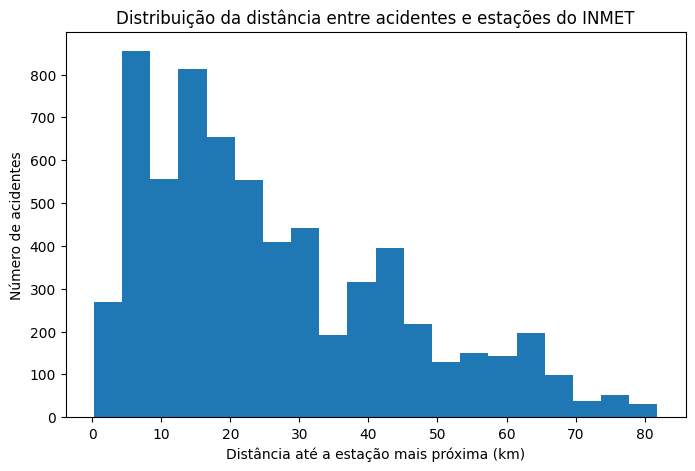

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    base["distancia_estacao_km"].dropna(),
    bins=20
)

plt.xlabel("Distância até a estação mais próxima (km)")
plt.ylabel("Número de acidentes")
plt.title("Distribuição da distância entre acidentes e estações do INMET")

plt.show()

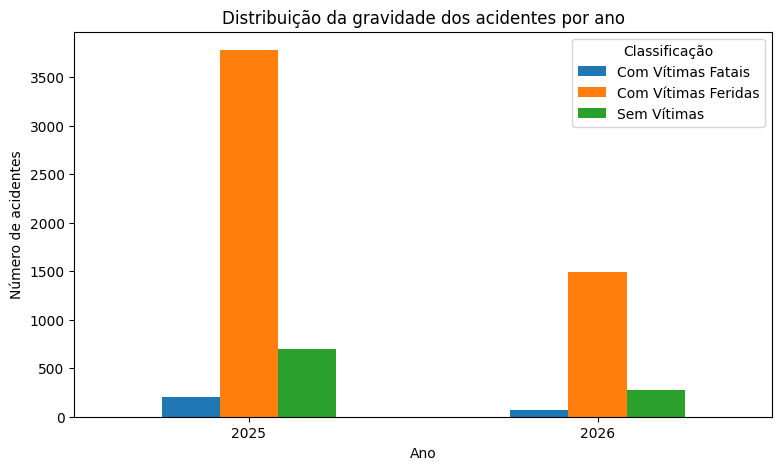

In [ ]:
gravidade_por_ano = pd.crosstab(
    base["ano"],
    base["classificacao_acidente"]
)

gravidade_por_ano.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.xlabel("Ano")
plt.ylabel("Número de acidentes")
plt.title("Distribuição da gravidade dos acidentes por ano")
plt.xticks(rotation=0)
plt.legend(title="Classificação")

plt.show()

# 6. Análise descritiva

O script de análise descritiva apresenta estatísticas gerais da base integrada e análises de qualidade dos dados.

Além das distribuições de gravidade, precipitação, distância e diferença temporal, são avaliados:

- a concordância entre a condição meteorológica registrada pela PRF e a precipitação medida pelo INMET;
- o impacto de diferentes limites de distância entre acidentes e estações meteorológicas;
- os maiores valores de precipitação observados na base.

Essas análises serão utilizadas para definir os critérios da base final antes da modelagem estatística.

In [ ]:
!python src/04_analise_descritiva.py


ANÁLISE DESCRITIVA

Quantidade total de acidentes:
6515

Acidentes por ano:
ano
2025    4683
2026    1832
Name: count, dtype: int64

Gravidade:
classificacao_acidente
Com Vítimas Feridas    5273
Sem Vítimas             971
Com Vítimas Fatais      271
Name: count, dtype: int64

Gravidade por ano:
classificacao_acidente  Com Vítimas Fatais  Com Vítimas Feridas  Sem Vítimas
ano                                                                         
2025                                   205                 3779          699
2026                                    66                 1494          272

Status da integração:
status_integracao
integrado               5661
precipitacao_ausente     854
Name: count, dtype: int64

Status da integração por ano:
status_integracao  integrado  precipitacao_ausente
ano                                               
2025                    3982                   701
2026                    1679                   153

Precipitação:
count    5661.00000

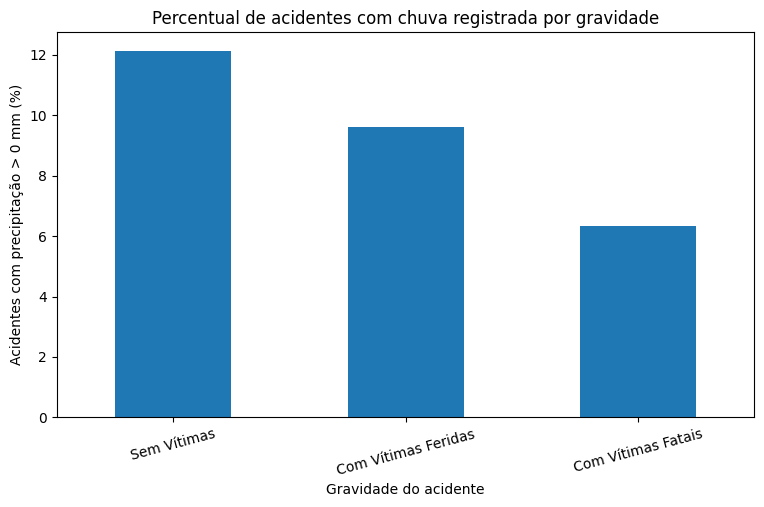

In [ ]:
dados_validos = base[
    base["precipitacao_mm"].notna()
].copy()

dados_validos["teve_chuva"] = (
    dados_validos["precipitacao_mm"] > 0
)

ordem = [
    "Sem Vítimas",
    "Com Vítimas Feridas",
    "Com Vítimas Fatais"
]

chuva_por_gravidade = (
    dados_validos
    .groupby(
        "classificacao_acidente"
    )["teve_chuva"]
    .mean()
    .mul(100)
    .reindex(ordem)
)

plt.figure(
    figsize=(9, 5)
)

chuva_por_gravidade.plot(
    kind="bar"
)

plt.xlabel(
    "Gravidade do acidente"
)

plt.ylabel(
    "Acidentes com precipitação > 0 mm (%)"
)

plt.title(
    "Percentual de acidentes com chuva registrada por gravidade"
)

plt.xticks(
    rotation=15
)

plt.show()

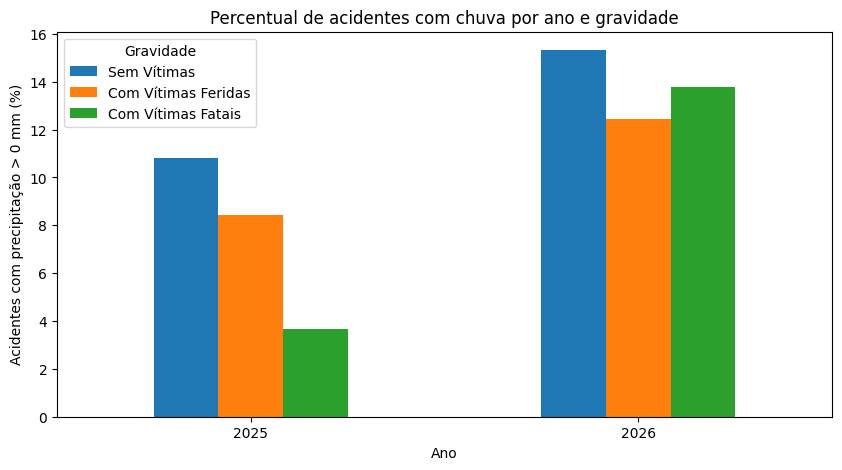

In [ ]:
chuva_ano_gravidade = (
    dados_validos
    .groupby(
        [
            "ano",
            "classificacao_acidente"
        ]
    )["teve_chuva"]
    .mean()
    .mul(100)
    .unstack()
)

chuva_ano_gravidade = (
    chuva_ano_gravidade[
        ordem
    ]
)

chuva_ano_gravidade.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.xlabel("Ano")

plt.ylabel(
    "Acidentes com precipitação > 0 mm (%)"
)

plt.title(
    "Percentual de acidentes com chuva por ano e gravidade"
)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Gravidade"
)

plt.show()

# 7. Regressão Logística Ordinal

A Regressão Logística Ordinal será utilizada para avaliar a associação entre precipitação e gravidade dos acidentes.

A variável resposta é organizada em:

- **0 — Sem vítimas**
- **1 — Com vítimas feridas**
- **2 — Com vítimas fatais**

Serão considerados inicialmente:

**Modelo 1 — associação bruta**

`gravidade ~ precipitacao`

**Modelo 2 — associação ajustada**

`gravidade ~ precipitacao + fase_dia + tipo_pista + tracado_via + ano + mes`

A modelagem deve ser executada somente após a validação da base integrada e da qualidade da associação espacial.

In [ ]:
!python src/05_regressao_ordinal.py


ANÁLISE DA ASSOCIAÇÃO ENTRE PRECIPITAÇÃO E GRAVIDADE

Quantidade inicial de acidentes: 6,515

DIAGNÓSTICO DOS DADOS AUSENTES DE PRECIPITAÇÃO

Precipitação ausente: 854 (13.11%)

Ausência por ano:
 ano  total  ausentes percentual_ausente
2025   4683       701             14.97%
2026   1832       153              8.35%

Ausência por mes:
 mes  total  ausentes percentual_ausente
   1    678       116             17.11%
   2    703       110             15.65%
   3    787       101             12.83%
   4    737       101             13.70%
   5    822        96             11.68%
   6    385        57             14.81%
   7    363        55             15.15%
   8    393        43             10.94%
   9    390        38              9.74%
  10    419        56             13.37%
  11    421        54             12.83%
  12    417        27              6.47%

Ausência por classificacao_acidente:
classificacao_acidente  total  ausentes percentual_ausente
    Com Vítimas Fatais    271  

# 8. Resultados e próximos passos

Nesta etapa deverão ser consolidados:

- tamanho final da amostra;
- quantidade de acidentes por ano e por gravidade;
- percentual de precipitação disponível;
- qualidade da correspondência espacial e temporal;
- critérios de exclusão adotados;
- resultados da Regressão Logística Ordinal;
- razões de chances (*odds ratios*);
- intervalos de confiança;
- significância estatística;
- avaliação da suposição de chances proporcionais;
- interpretação da associação entre precipitação e gravidade.

> **Importante:** diferenças descritivas entre as médias de precipitação das categorias de gravidade não devem ser interpretadas como evidência de associação antes da modelagem estatística.